# DBSCAN

DBSCAN is a clustering algorithm that groups together points that are closely packed together while marking points that are in low-density regions as outliers. The key concepts in DBSCAN are:

1- Epsilon (eps): The maximum distance between two samples for them to be considered as in the same neighborhood.

2- Min_samples: The number of samples (or total weight) in a neighborhood for a point to be considered as a core point. This includes the point itself.

In [1]:
# Import necessary libraries
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
import matplotlib.pyplot as plt
import numpy as np

from sklearn.metrics import silhouette_score

Steps Used In DBSCAN Algorithm

1- Find all the neighbor points within eps and identify the core points or visited with more than MinPts neighbors.

2-For each core point if it is not already assigned to a cluster, create a new cluster.

3- Find recursively all its density-connected points and assign them to the same cluster as the core point. 

4- A point a and b are said to be density connected if there exists a point c which has a sufficient number of points in its neighbors and both points a and b are within the eps distance. 

5- This is a chaining process. So, if b is a neighbor of c, c is a neighbor of d, and d is a neighbor of e, which in turn is  neighbor of a implying that b is a neighbor of a.

6- Iterate through the remaining unvisited points in the dataset. Those points that do not belong to any cluster are noise.

In this algorithm, we have 3 types of data points.

    1- Core Point: A point is a core point if it has more than MinPts points within eps. 
    
    2- Border Point: A point which has fewer than MinPts within eps but it is in the neighborhood of a core point. 
    
    3- Noise or outlier: A point which is not a core point or border point.


![alt text](ss.jpeg)

Evaluation Metrics For DBSCAN Algorithm In Machine Learning 

1- We will use the Silhouette score and Adjusted rand score for evaluating clustering algorithms. 

2- Silhouette’s score is in the range of -1 to 1. 

3- A score near 1 denotes the best meaning that the data point i is very compact within the cluster to which it belongs and far away from the other clusters. 

4- The worst value is -1. Values near 0 denote overlapping clusters.

5- Absolute Rand Score is in the range of 0 to 1. More than 0.9 denotes excellent cluster recovery, and above 0.8 is a good recovery. Less than 0.5 is considered to be poor recovery. 

In [2]:
# Load the Iris dataset
data = load_iris()

# Get the features (input)
X = data.data

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [3]:
# Initialize and fit DBSCAN
dbscan = DBSCAN(eps=0.5, min_samples=3)
dbscan.fit(X_scaled)

# Get the cluster labels
labels = dbscan.labels_
labels

array([ 0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0, -1, -1,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0, -1, -1,
        0,  0,  0,  0,  0,  0,  0, -1,  0,  0,  0,  0,  0,  0,  0,  0,  1,
        1,  1,  1,  1,  1,  1,  2,  1, -1, -1,  1, -1,  1,  1,  1,  1,  1,
        3,  1,  1,  1, -1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
        1,  1,  3,  1,  1,  1,  1,  1,  2,  1,  1,  1,  1,  2,  1,  6,  1,
        1,  1,  1,  4, -1,  5, -1, -1,  1,  1,  1,  1, -1,  1,  1, -1, -1,
        3,  1,  1,  4,  1,  1, -1,  1,  1,  1,  5,  5, -1,  1,  1,  1,  4,
        6,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  6,  1])

In [4]:
len(set(labels))

8

In [5]:
# Number of clusters in labels, ignoring noise if present
n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
n_noise_ = list(labels).count(-1)


print('Estimated number of clusters: %d' % n_clusters_)
print('Estimated number of noise points: %d' % n_noise_)

Estimated number of clusters: 7
Estimated number of noise points: 17


In [6]:
# Calculate the silhouette score
# Silhouette score is only defined if the number of labels is more than 1 and less than the number of samples
if len(set(labels)) > 1 and len(set(labels)) < len(X):
    silhouette_avg = silhouette_score(X_scaled, labels)
    print(f'Silhouette Score: {silhouette_avg:.3f}')
else:
    print("Silhouette Score is not defined for the given number of clusters.")

Silhouette Score: 0.160


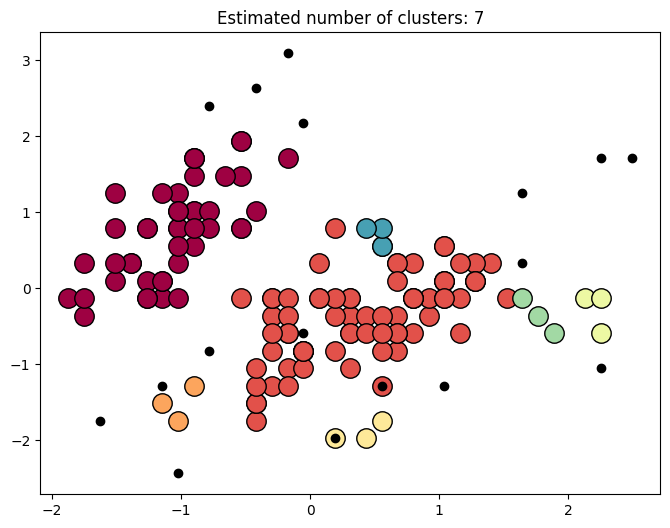

In [27]:
# Plotting the results
plt.figure(figsize=(8, 6))

# Black removed and is used for noise instead.
unique_labels = set(labels)
colors = [plt.cm.Spectral(each)
          for each in np.linspace(0, 1, len(unique_labels))]
for k, col in zip(unique_labels, colors):
    if k == -1:
        # Black used for noise.
        col = [0, 0, 0, 1]

    class_member_mask = (labels == k)

    xy = X_scaled[class_member_mask & (labels != -1)]
    plt.plot(xy[:, 0], xy[:, 1], 'o', markerfacecolor=tuple(col),
             markeredgecolor='k', markersize=14)

    xy = X_scaled[class_member_mask & (labels == -1)]
    plt.plot(xy[:, 0], xy[:, 1], 'o', markerfacecolor=tuple(col),
             markeredgecolor='k', markersize=6)

plt.title('Estimated number of clusters: %d' % n_clusters_)
plt.show()

In [ ]:
# evaluate DBSCAN 

silhouette_score = np.zeros(n_clusters) 

![alt text](<DBSCAN vs K means.PNG>)

![alt text](<DBSCAN vs K means visualize.PNG>)

In [28]:
# Import necessary libraries
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

In [29]:
# Load the Iris dataset
data = load_iris()
X = data.data

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


In [30]:
# Initialize and fit DBSCAN
dbscan = DBSCAN(eps=0.5, min_samples=5)
dbscan.fit(X_scaled)

# Get the cluster labels
labels = dbscan.labels_

# Calculate the silhouette score
# Silhouette score is only defined if the number of labels is more than 1 and less than the number of samples
if len(set(labels)) > 1 and len(set(labels)) < len(X):
    silhouette_avg = silhouette_score(X_scaled, labels)
    print(f'Silhouette Score: {silhouette_avg:.3f}')
else:
    print("Silhouette Score is not defined for the given number of clusters.")

Silhouette Score: 0.357


In [31]:
# Number of clusters in labels, ignoring noise if present
n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
n_noise_ = list(labels).count(-1)

print('Estimated number of clusters: %d' % n_clusters_)
print('Estimated number of noise points: %d' % n_noise_)

Estimated number of clusters: 2
Estimated number of noise points: 34


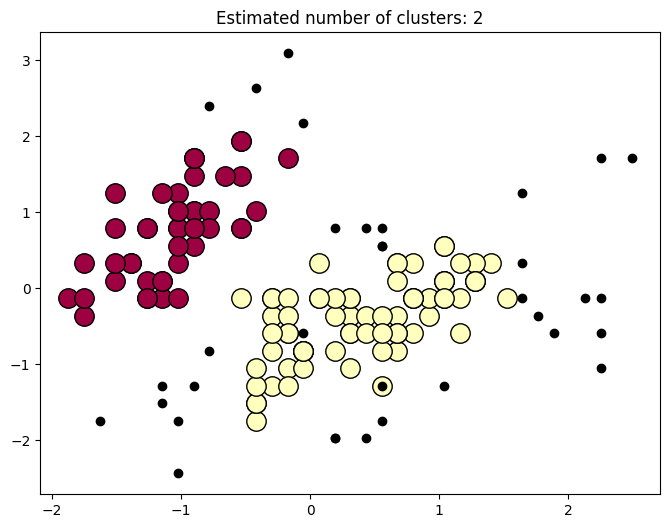

In [33]:
# Plotting the results
plt.figure(figsize=(8, 6))

# Black removed and is used for noise instead.
unique_labels = set(labels)
colors = [plt.cm.Spectral(each)
          for each in np.linspace(0, 1, len(unique_labels))]
for k, col in zip(unique_labels, colors):
    if k == -1:
        # Black used for noise.
        col = [0, 0, 0, 1]

    class_member_mask = (labels == k)

    xy = X_scaled[class_member_mask & (labels != -1)]
    plt.plot(xy[:, 0], xy[:, 1], 'o', markerfacecolor=tuple(col),
             markeredgecolor='k', markersize=14)

    xy = X_scaled[class_member_mask & (labels == -1)]
    plt.plot(xy[:, 0], xy[:, 1], 'o', markerfacecolor=tuple(col),
             markeredgecolor='k', markersize=6)

plt.title('Estimated number of clusters: %d' % n_clusters_)
plt.show()